In [1]:
from google.colab import drive
drive.mount('/content/drive')
print("✅ Drive mounted!")

Mounted at /content/drive
✅ Drive mounted!


In [2]:
import os

base_path = '/content/drive/MyDrive'
print(os.listdir(base_path))

['Classroom', 'X & XII marksheet (1).pdf', 'X & XII marksheet.pdf', 'smart-attendance-system', 'Colab Notebooks', 'qwen_astrologer_merged', 'SDE_Disha Agrawal', 'Disha_placement ~.pdf', 'DishaR ~.pdf', 'Untitled presentation.gslides', 'Brain Tumor MRI']


In [3]:
brain_path = '/content/drive/MyDrive/Brain Tumor MRI'
print(os.listdir(brain_path))

['train-20260929T064620Z-1-001', 'valid-20260929T064705Z-1-001', 'test-20260929T064624Z-1-001', 'custom_cnn_checkpoint.h5', 'transfer_model_checkpoint.h5']


In [4]:
train_path = '/content/drive/MyDrive/Brain Tumor MRI/train-20260929T064620Z-1-001'
print(os.listdir(train_path))


['train']


In [5]:
train_path = '/content/drive/MyDrive/Brain Tumor MRI/train-20260929T064620Z-1-001/train'
print(os.listdir(train_path))


['_classes.csv', 'meningioma', 'glioma', 'pituitary', 'no_tumor']


In [6]:
for class_name in os.listdir(train_path):
    class_folder = os.path.join(train_path, class_name)
    if os.path.isdir(class_folder):
        num_images = len(os.listdir(class_folder))
        print(f"{class_name}: {num_images} images")

meningioma: 358 images
glioma: 566 images
pituitary: 438 images
no_tumor: 336 images


In [7]:
from google.colab import drive
drive.mount('/content/drive')

import os
train_path = '/content/drive/MyDrive/Brain Tumor MRI/train-20260929T064620Z-1-001/train'
valid_path = '/content/drive/MyDrive/Brain Tumor MRI/valid-20260929T064705Z-1-001/valid'
test_path = '/content/drive/MyDrive/Brain Tumor MRI/test-20260929T064624Z-1-001/test'

from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = 224
BATCH_SIZE = 32

valid_test_datagen = ImageDataGenerator(rescale=1./255)

test_generator = valid_test_datagen.flow_from_directory(
    test_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

print("Setup complete!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Found 246 images belonging to 4 classes.
Setup complete!


In [8]:
import tensorflow as tf
print("GPU available:", tf.config.list_physical_devices('GPU'))

GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


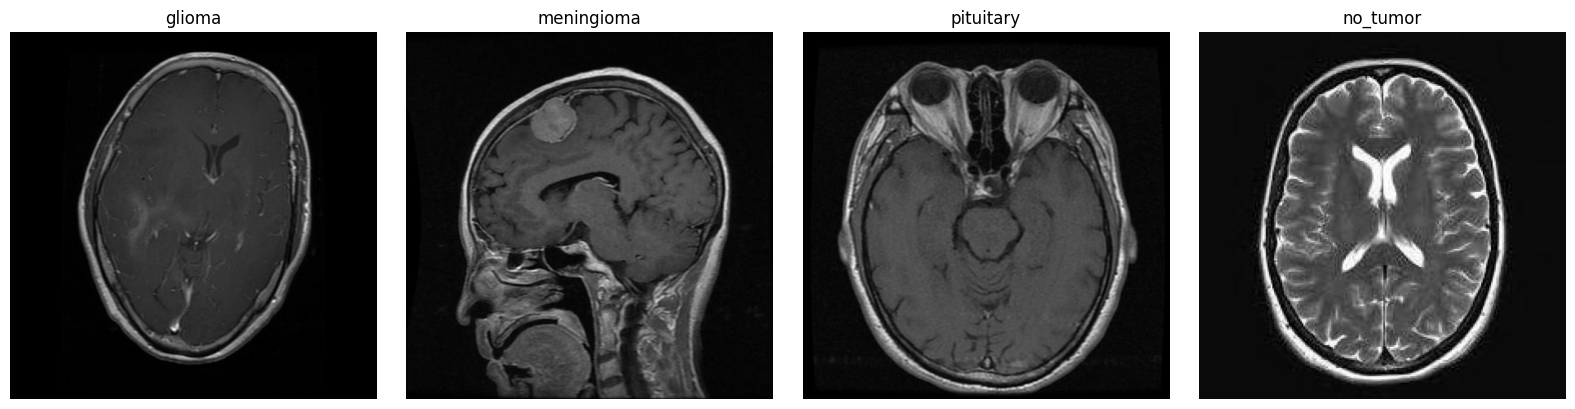

Image shape: (640, 640, 3)


In [9]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

classes = ['glioma', 'meningioma', 'pituitary', 'no_tumor']

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for i, class_name in enumerate(classes):
    class_folder = os.path.join(train_path, class_name)
    sample_image = os.listdir(class_folder)[0]
    img_path = os.path.join(class_folder, sample_image)
    img = mpimg.imread(img_path)
    axes[i].imshow(img, cmap='gray')
    axes[i].set_title(class_name)
    axes[i].axis('off')

plt.tight_layout()
plt.show()

# Also check image dimensions
sample_img = mpimg.imread(os.path.join(train_path, 'glioma', os.listdir(os.path.join(train_path, 'glioma'))[0]))
print("Image shape:", sample_img.shape)

In [10]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = 224
BATCH_SIZE = 32

# Training data with augmentation
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    zoom_range=0.1,
    brightness_range=[0.9, 1.1]
)

# Validation and test data - only rescaling, no augmentation
valid_test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    train_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True
)

valid_generator = valid_test_datagen.flow_from_directory(
    valid_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

test_generator = valid_test_datagen.flow_from_directory(
    test_path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

print("Class indices:", train_generator.class_indices)

Found 1698 images belonging to 4 classes.
Found 502 images belonging to 4 classes.
Found 246 images belonging to 4 classes.
Class indices: {'glioma': 0, 'meningioma': 1, 'no_tumor': 2, 'pituitary': 3}


In [11]:
from tensorflow.keras import layers, models

def build_custom_cnn(input_shape=(224, 224, 3), num_classes=4):
    model = models.Sequential([
        layers.Conv2D(32, (3,3), activation='relu', input_shape=input_shape),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2,2),

        layers.Conv2D(64, (3,3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2,2),

        layers.Conv2D(128, (3,3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2,2),

        layers.Conv2D(256, (3,3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2,2),

        layers.Flatten(),
        layers.Dense(256, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax')
    ])
    return model

custom_cnn = build_custom_cnn()
custom_cnn.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

custom_cnn.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 222, 222, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 109, 109, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 52, 52, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 24, 24, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36864)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     9,437,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,828,804 (37.49 MB)

 Trainable params: 9,827,844 (37.49 MB)

 Non-trainable params: 960 (3.75 KB)

In [12]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
checkpoint = ModelCheckpoint('custom_cnn_best.h5', monitor='val_accuracy', save_best_only=True)

history_cnn = custom_cnn.fit(
    train_generator,
    validation_data=valid_generator,
    epochs=25,
    callbacks=[early_stop, checkpoint]
)

Epoch 1/25
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 18s/step - accuracy: 0.5121 - loss: 9.0666 

54/54 ━━━━━━━━━━━━━━━━━━━━ 1328s 24s/step - accuracy: 0.5565 - loss: 5.3881 - val_accuracy: 0.2311 - val_loss: 3.8090
Epoch 2/25
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 572ms/step - accuracy: 0.5833 - loss: 1.2302

54/54 ━━━━━━━━━━━━━━━━━━━━ 34s 616ms/step - accuracy: 0.5942 - loss: 1.1110 - val_accuracy: 0.2371 - val_loss: 10.1214
Epoch 3/25
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 567ms/step - accuracy: 0.6018 - loss: 1.0390

54/54 ━━━━━━━━━━━━━━━━━━━━ 33s 613ms/step - accuracy: 0.6160 - loss: 1.0389 - val_accuracy: 0.3068 - val_loss: 3.6534
Epoch 4/25
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 561ms/step - accuracy: 0.5990 - loss: 1.0290

54/54 ━━━━━━━━━━━━━━━━━━━━ 33s 614ms/step - accuracy: 0.6278 - loss: 0.9935 - val_accuracy: 0.3207 - val_loss: 8.6446
Epoch 5/25
54/54 ━━━━━━━━━━━━━━━━━━━━ 33s 604ms/step - accuracy: 0.6290 - loss: 0.9798 - val_accuracy: 0.2669 - val_loss: 2.7087
Epoch 6/25
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 563ms/step - accuracy: 0.6145 - loss: 0.9633

...

54/54 ━━━━━━━━━━━━━━━━━━━━ 33s 605ms/step - accuracy: 0.6625 - loss: 0.8448 - val_accuracy: 0.5657 - val_loss: 1.2706
Epoch 9/25
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 559ms/step - accuracy: 0.6721 - loss: 0.8744

54/54 ━━━━━━━━━━━━━━━━━━━━ 33s 607ms/step - accuracy: 0.6802 - loss: 0.8715 - val_accuracy: 0.5996 - val_loss: 1.0512
Epoch 10/25
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 561ms/step - accuracy: 0.6097 - loss: 0.9539

54/54 ━━━━━━━━━━━━━━━━━━━━ 33s 611ms/step - accuracy: 0.5954 - loss: 0.9829 - val_accuracy: 0.6036 - val_loss: 1.0868
Epoch 11/25
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 553ms/step - accuracy: 0.6003 - loss: 0.8942

54/54 ━━━━━━━━━━━━━━━━━━━━ 32s 596ms/step - accuracy: 0.6072 - loss: 0.8821 - val_accuracy: 0.7072 - val_loss: 0.7198
Epoch 12/25
54/54 ━━━━━━━━━━━━━━━━━━━━ 32s 596ms/step - accuracy: 0.6060 - loss: 0.8788 - val_accuracy: 0.5279 - val_loss: 1.0604
Epoch 13/25
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 569ms/step - accuracy: 0.6396 - loss: 0.8439

54/54 ━━━━━━━━━━━━━━━━━━━━ 34s 624ms/step - accuracy: 0.6319 - loss: 0.8658 - val_accuracy: 0.7450 - val_loss: 0.6835
Epoch 14/25
54/54 ━━━━━━━━━━━━━━━━━━━━ 32s 601ms/step - accuracy: 0.6372 - loss: 0.8189 - val_accuracy: 0.7231 - val_loss: 0.7509
Epoch 15/25
54/54 ━━━━━━━━━━━━━━━━━━━━ 32s 600ms/step - accuracy: 0.6514 - loss: 0.7817 - val_accuracy: 0.5837 - val_loss: 2.1471
Epoch 16/25
54/54 ━━━━━━━━━━━━━━━━━━━━ 34s 625ms/step - accuracy: 0.6254 - loss: 0.8491 - val_accuracy: 0.6335 - val_loss: 0.9299
Epoch 17/25
54/54 ━━━━━━━━━━━━━━━━━━━━ 33s 605ms/step - accuracy: 0.6625 - loss: 0.8019 - val_accuracy: 0.4801 - val_loss: 2.4626
Epoch 18/25
54/54 ━━━━━━━━━━━━━━━━━━━━ 33s 607ms/step - accuracy: 0.6961 - loss: 0.7569 - val_accuracy: 0.3665 - val_loss: 2.4168


In [13]:
history_cnn = custom_cnn.fit(
    train_generator,
    validation_data=valid_generator,
    epochs=25,
    callbacks=[early_stop, checkpoint]
)

Epoch 1/25
54/54 ━━━━━━━━━━━━━━━━━━━━ 32s 602ms/step - accuracy: 0.6360 - loss: 0.8341 - val_accuracy: 0.7390 - val_loss: 0.8734
Epoch 2/25
54/54 ━━━━━━━━━━━━━━━━━━━━ 34s 626ms/step - accuracy: 0.6561 - loss: 0.7865 - val_accuracy: 0.6414 - val_loss: 0.8728
Epoch 3/25
54/54 ━━━━━━━━━━━━━━━━━━━━ 33s 610ms/step - accuracy: 0.6237 - loss: 0.9362 - val_accuracy: 0.1972 - val_loss: 22.5146
Epoch 4/25
54/54 ━━━━━━━━━━━━━━━━━━━━ 32s 595ms/step - accuracy: 0.6166 - loss: 1.0384 - val_accuracy: 0.5538 - val_loss: 1.8062
Epoch 5/25
54/54 ━━━━━━━━━━━━━━━━━━━━ 33s 611ms/step - accuracy: 0.6001 - loss: 1.0270 - val_accuracy: 0.7072 - val_loss: 0.8409


In [14]:
# Save model after every epoch to Drive (so progress isn't lost)
checkpoint = ModelCheckpoint(
    '/content/drive/MyDrive/Brain Tumor MRI/custom_cnn_checkpoint.h5',
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1
)

In [15]:
history_cnn = custom_cnn.fit(
    train_generator,
    validation_data=valid_generator,
    epochs=25,
    callbacks=[early_stop, checkpoint]
)

Epoch 1/25
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 563ms/step - accuracy: 0.6302 - loss: 0.8059
Epoch 1: val_accuracy improved from None to 0.61952, saving model to /content/drive/MyDrive/Brain Tumor MRI/custom_cnn_checkpoint.h5



Epoch 1: finished saving model to /content/drive/MyDrive/Brain Tumor MRI/custom_cnn_checkpoint.h5
54/54 ━━━━━━━━━━━━━━━━━━━━ 42s 785ms/step - accuracy: 0.6461 - loss: 0.8112 - val_accuracy: 0.6195 - val_loss: 1.7901
Epoch 2/25
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 617ms/step - accuracy: 0.6678 - loss: 0.8102
Epoch 2: val_accuracy did not improve from 0.61952
54/54 ━━━━━━━━━━━━━━━━━━━━ 36s 663ms/step - accuracy: 0.6625 - loss: 0.8599 - val_accuracy: 0.1972 - val_loss: 17.9358
Epoch 3/25
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 567ms/step - accuracy: 0.6323 - loss: 0.8694
Epoch 3: val_accuracy did not improve from 0.61952
54/54 ━━━━━━━━━━━━━━━━━━━━ 33s 606ms/step - accuracy: 0.6537 - loss: 0.8403 - val_accuracy: 0.5518 - val_loss: 1.2254
Epoch 4/25
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 564ms/step - accuracy: 0.6995 - loss: 0.6884
Epoch 4: val_accuracy improved from 0.61952 to 0.71514, saving model to /content/drive/MyDrive/Brain Tumor MRI/custom_cnn_checkpoint.h5



Epoch 4: finished saving model to /content/drive/MyDrive/Brain Tumor MRI/custom_cnn_checkpoint.h5
54/54 ━━━━━━━━━━━━━━━━━━━━ 35s 655ms/step - accuracy: 0.7079 - loss: 0.7401 - val_accuracy: 0.7151 - val_loss: 0.7280
Epoch 5/25
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 615ms/step - accuracy: 0.6508 - loss: 0.7865
Epoch 5: val_accuracy did not improve from 0.71514
54/54 ━━━━━━━━━━━━━━━━━━━━ 41s 659ms/step - accuracy: 0.6390 - loss: 0.7860 - val_accuracy: 0.3665 - val_loss: 5.2174


In [16]:
import tensorflow as tf
print("GPU available:", tf.config.list_physical_devices('GPU'))

GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [17]:
from tensorflow.keras.models import load_model

custom_cnn = load_model('/content/drive/MyDrive/Brain Tumor MRI/custom_cnn_checkpoint.h5')

# Recompile with a fresh optimizer instance
custom_cnn.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history_cnn = custom_cnn.fit(
    train_generator,
    validation_data=valid_generator,
    epochs=5,
    callbacks=[early_stop, checkpoint]
)

Epoch 1/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 608ms/step - accuracy: 0.6260 - loss: 0.9451
Epoch 1: val_accuracy did not improve from 0.71514
54/54 ━━━━━━━━━━━━━━━━━━━━ 44s 674ms/step - accuracy: 0.6137 - loss: 0.9799 - val_accuracy: 0.2131 - val_loss: 5.3021
Epoch 2/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 579ms/step - accuracy: 0.6635 - loss: 0.8673
Epoch 2: val_accuracy did not improve from 0.71514
54/54 ━━━━━━━━━━━━━━━━━━━━ 34s 620ms/step - accuracy: 0.6655 - loss: 0.8867 - val_accuracy: 0.5857 - val_loss: 3.1611
Epoch 3/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 569ms/step - accuracy: 0.6396 - loss: 0.8169
Epoch 3: val_accuracy improved from 0.71514 to 0.75896, saving model to /content/drive/MyDrive/Brain Tumor MRI/custom_cnn_checkpoint.h5



Epoch 3: finished saving model to /content/drive/MyDrive/Brain Tumor MRI/custom_cnn_checkpoint.h5
54/54 ━━━━━━━━━━━━━━━━━━━━ 33s 616ms/step - accuracy: 0.6690 - loss: 0.7578 - val_accuracy: 0.7590 - val_loss: 0.8719
Epoch 4/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 630ms/step - accuracy: 0.7182 - loss: 0.7329
Epoch 4: val_accuracy did not improve from 0.75896
54/54 ━━━━━━━━━━━━━━━━━━━━ 36s 676ms/step - accuracy: 0.7073 - loss: 0.7506 - val_accuracy: 0.6295 - val_loss: 1.1841
Epoch 5/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 564ms/step - accuracy: 0.6696 - loss: 0.8050
Epoch 5: val_accuracy did not improve from 0.75896
54/54 ━━━━━━━━━━━━━━━━━━━━ 33s 604ms/step - accuracy: 0.6826 - loss: 0.9014 - val_accuracy: 0.6036 - val_loss: 2.1624


In [18]:
from tensorflow.keras.callbacks import ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

# Recompile with a lower, more stable learning rate
custom_cnn.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1)

history_cnn = custom_cnn.fit(
    train_generator,
    validation_data=valid_generator,
    epochs=5,
    callbacks=[early_stop, checkpoint, reduce_lr]
)

Epoch 1/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 606ms/step - accuracy: 0.6788 - loss: 0.7959
Epoch 1: val_accuracy improved from 0.75896 to 0.79681, saving model to /content/drive/MyDrive/Brain Tumor MRI/custom_cnn_checkpoint.h5



Epoch 1: finished saving model to /content/drive/MyDrive/Brain Tumor MRI/custom_cnn_checkpoint.h5
54/54 ━━━━━━━━━━━━━━━━━━━━ 47s 728ms/step - accuracy: 0.6896 - loss: 0.7538 - val_accuracy: 0.7968 - val_loss: 0.7123 - learning_rate: 1.0000e-04
Epoch 2/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 611ms/step - accuracy: 0.7028 - loss: 0.7304
Epoch 2: val_accuracy improved from 0.79681 to 0.81275, saving model to /content/drive/MyDrive/Brain Tumor MRI/custom_cnn_checkpoint.h5



Epoch 2: finished saving model to /content/drive/MyDrive/Brain Tumor MRI/custom_cnn_checkpoint.h5
54/54 ━━━━━━━━━━━━━━━━━━━━ 38s 701ms/step - accuracy: 0.7161 - loss: 0.7056 - val_accuracy: 0.8127 - val_loss: 0.5489 - learning_rate: 1.0000e-04
Epoch 3/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 627ms/step - accuracy: 0.7241 - loss: 0.6278
Epoch 3: val_accuracy did not improve from 0.81275
54/54 ━━━━━━━━━━━━━━━━━━━━ 36s 666ms/step - accuracy: 0.7261 - loss: 0.6272 - val_accuracy: 0.7610 - val_loss: 0.7985 - learning_rate: 1.0000e-04
Epoch 4/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 561ms/step - accuracy: 0.7665 - loss: 0.5660
Epoch 4: val_accuracy did not improve from 0.81275

Epoch 4: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
54/54 ━━━━━━━━━━━━━━━━━━━━ 32s 600ms/step - accuracy: 0.7538 - loss: 0.5940 - val_accuracy: 0.7550 - val_loss: 0.9021 - learning_rate: 1.0000e-04
Epoch 5/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 571ms/step - accuracy: 0.7681 - loss: 0.5924
Epoch 5: val_accuracy did not

In [19]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model

base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False  # freeze pretrained layers initially

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)
predictions = Dense(4, activation='softmax')(x)

transfer_model = Model(inputs=base_model.input, outputs=predictions)

transfer_model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

transfer_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional_17"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [20]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

early_stop_tf = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
checkpoint_tf = ModelCheckpoint(
    '/content/drive/MyDrive/Brain Tumor MRI/transfer_model_checkpoint.h5',
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1
)
reduce_lr_tf = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1)

history_transfer = transfer_model.fit(
    train_generator,
    validation_data=valid_generator,
    epochs=5,
    callbacks=[early_stop_tf, checkpoint_tf, reduce_lr_tf]
)

Epoch 1/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 598ms/step - accuracy: 0.4332 - loss: 1.2644
Epoch 1: val_accuracy improved from None to 0.66534, saving model to /content/drive/MyDrive/Brain Tumor MRI/transfer_model_checkpoint.h5



Epoch 1: finished saving model to /content/drive/MyDrive/Brain Tumor MRI/transfer_model_checkpoint.h5
54/54 ━━━━━━━━━━━━━━━━━━━━ 56s 837ms/step - accuracy: 0.5359 - loss: 1.1114 - val_accuracy: 0.6653 - val_loss: 0.8374 - learning_rate: 1.0000e-04
Epoch 2/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 546ms/step - accuracy: 0.6870 - loss: 0.8144
Epoch 2: val_accuracy improved from 0.66534 to 0.73108, saving model to /content/drive/MyDrive/Brain Tumor MRI/transfer_model_checkpoint.h5



Epoch 2: finished saving model to /content/drive/MyDrive/Brain Tumor MRI/transfer_model_checkpoint.h5
54/54 ━━━━━━━━━━━━━━━━━━━━ 33s 615ms/step - accuracy: 0.7173 - loss: 0.7578 - val_accuracy: 0.7311 - val_loss: 0.6668 - learning_rate: 1.0000e-04
Epoch 3/5
53/54 ━━━━━━━━━━━━━━━━━━━━ 0s 556ms/step - accuracy: 0.7785 - loss: 0.6124
Epoch 3: val_accuracy improved from 0.73108 to 0.76494, saving model to /content/drive/MyDrive/Brain Tumor MRI/transfer_model_checkpoint.h5



Epoch 3: finished saving model to /content/drive/MyDrive/Brain Tumor MRI/transfer_model_checkpoint.h5
54/54 ━━━━━━━━━━━━━━━━━━━━ 33s 620ms/step - accuracy: 0.7956 - loss: 0.5758 - val_accuracy: 0.7649 - val_loss: 0.5736 - learning_rate: 1.0000e-04
Epoch 4/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 546ms/step - accuracy: 0.8091 - loss: 0.5283
Epoch 4: val_accuracy did not improve from 0.76494
54/54 ━━━━━━━━━━━━━━━━━━━━ 32s 586ms/step - accuracy: 0.8110 - loss: 0.5147 - val_accuracy: 0.7490 - val_loss: 0.5811 - learning_rate: 1.0000e-04
Epoch 5/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 540ms/step - accuracy: 0.8185 - loss: 0.4869
Epoch 5: val_accuracy improved from 0.76494 to 0.81474, saving model to /content/drive/MyDrive/Brain Tumor MRI/transfer_model_checkpoint.h5



Epoch 5: finished saving model to /content/drive/MyDrive/Brain Tumor MRI/transfer_model_checkpoint.h5
54/54 ━━━━━━━━━━━━━━━━━━━━ 33s 607ms/step - accuracy: 0.8298 - loss: 0.4804 - val_accuracy: 0.8147 - val_loss: 0.4782 - learning_rate: 1.0000e-04


In [21]:
history_transfer2 = transfer_model.fit(
    train_generator,
    validation_data=valid_generator,
    epochs=5,
    callbacks=[early_stop_tf, checkpoint_tf, reduce_lr_tf]
)

Epoch 1/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 546ms/step - accuracy: 0.8387 - loss: 0.4335
Epoch 1: val_accuracy did not improve from 0.81474
54/54 ━━━━━━━━━━━━━━━━━━━━ 32s 601ms/step - accuracy: 0.8416 - loss: 0.4364 - val_accuracy: 0.7829 - val_loss: 0.5289 - learning_rate: 1.0000e-04
Epoch 2/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 552ms/step - accuracy: 0.8594 - loss: 0.4125
Epoch 2: val_accuracy did not improve from 0.81474

Epoch 2: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
54/54 ━━━━━━━━━━━━━━━━━━━━ 32s 592ms/step - accuracy: 0.8657 - loss: 0.3940 - val_accuracy: 0.7968 - val_loss: 0.4915 - learning_rate: 1.0000e-04
Epoch 3/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 543ms/step - accuracy: 0.8554 - loss: 0.3800
Epoch 3: val_accuracy did not improve from 0.81474
54/54 ━━━━━━━━━━━━━━━━━━━━ 31s 582ms/step - accuracy: 0.8539 - loss: 0.3828 - val_accuracy: 0.7908 - val_loss: 0.5023 - learning_rate: 5.0000e-05
Epoch 4/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 541ms/step - accuracy: 0.8675 - loss:


Epoch 4: finished saving model to /content/drive/MyDrive/Brain Tumor MRI/transfer_model_checkpoint.h5
54/54 ━━━━━━━━━━━━━━━━━━━━ 33s 619ms/step - accuracy: 0.8604 - loss: 0.3785 - val_accuracy: 0.8167 - val_loss: 0.4772 - learning_rate: 5.0000e-05
Epoch 5/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 549ms/step - accuracy: 0.8507 - loss: 0.3952
Epoch 5: val_accuracy did not improve from 0.81673
54/54 ━━━━━━━━━━━━━━━━━━━━ 32s 590ms/step - accuracy: 0.8628 - loss: 0.3644 - val_accuracy: 0.7988 - val_loss: 0.4767 - learning_rate: 5.0000e-05


In [22]:
# Unfreeze the top layers of the base model for fine-tuning
base_model.trainable = True

# Freeze all layers except the last 30
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Recompile with a very low learning rate (important for fine-tuning)
transfer_model.compile(
    optimizer=Adam(learning_rate=0.00001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history_finetune = transfer_model.fit(
    train_generator,
    validation_data=valid_generator,
    epochs=5,
    callbacks=[early_stop_tf, checkpoint_tf, reduce_lr_tf]
)

Epoch 1/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 680ms/step - accuracy: 0.5342 - loss: 1.2716
Epoch 1: val_accuracy did not improve from 0.81673
54/54 ━━━━━━━━━━━━━━━━━━━━ 60s 824ms/step - accuracy: 0.6072 - loss: 1.0317 - val_accuracy: 0.7649 - val_loss: 0.5642 - learning_rate: 1.0000e-05
Epoch 2/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 560ms/step - accuracy: 0.7792 - loss: 0.6108
Epoch 2: val_accuracy did not improve from 0.81673

Epoch 2: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
54/54 ━━━━━━━━━━━━━━━━━━━━ 62s 599ms/step - accuracy: 0.7992 - loss: 0.5520 - val_accuracy: 0.7311 - val_loss: 0.7013 - learning_rate: 1.0000e-05
Epoch 3/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 553ms/step - accuracy: 0.8405 - loss: 0.4635
Epoch 3: val_accuracy did not improve from 0.81673
54/54 ━━━━━━━━━━━━━━━━━━━━ 32s 595ms/step - accuracy: 0.8457 - loss: 0.4462 - val_accuracy: 0.7331 - val_loss: 0.7074 - learning_rate: 5.0000e-06
Epoch 4/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 553ms/step - accuracy: 0.8361 - loss:

In [23]:
from tensorflow.keras.models import load_model

# Load the best transfer learning model (83.47% val_accuracy)
best_model = load_model('/content/drive/MyDrive/Brain Tumor MRI/transfer_model_checkpoint.h5')

# Evaluate on the test set (data it has never seen)
test_loss, test_accuracy = best_model.evaluate(test_generator)
print(f"Test Accuracy: {test_accuracy*100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

8/8 ━━━━━━━━━━━━━━━━━━━━ 145s 20s/step - accuracy: 0.8049 - loss: 0.5067
Test Accuracy: 80.49%
Test Loss: 0.5067


In [24]:
# Load the best custom CNN model
custom_cnn_best = load_model('/content/drive/MyDrive/Brain Tumor MRI/custom_cnn_checkpoint.h5')

test_loss_cnn, test_accuracy_cnn = custom_cnn_best.evaluate(test_generator)
print(f"Custom CNN Test Accuracy: {test_accuracy_cnn*100:.2f}%")
print(f"Custom CNN Test Loss: {test_loss_cnn:.4f}")

print("\n--- Comparison ---")
print(f"Custom CNN:        {test_accuracy_cnn*100:.2f}%")
print(f"Transfer Learning:  {test_accuracy*100:.2f}%")

8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 185ms/step - accuracy: 0.8252 - loss: 0.5312
Custom CNN Test Accuracy: 82.52%
Custom CNN Test Loss: 0.5312

--- Comparison ---
Custom CNN:        82.52%
Transfer Learning:  80.49%


8/8 ━━━━━━━━━━━━━━━━━━━━ 5s 404ms/step


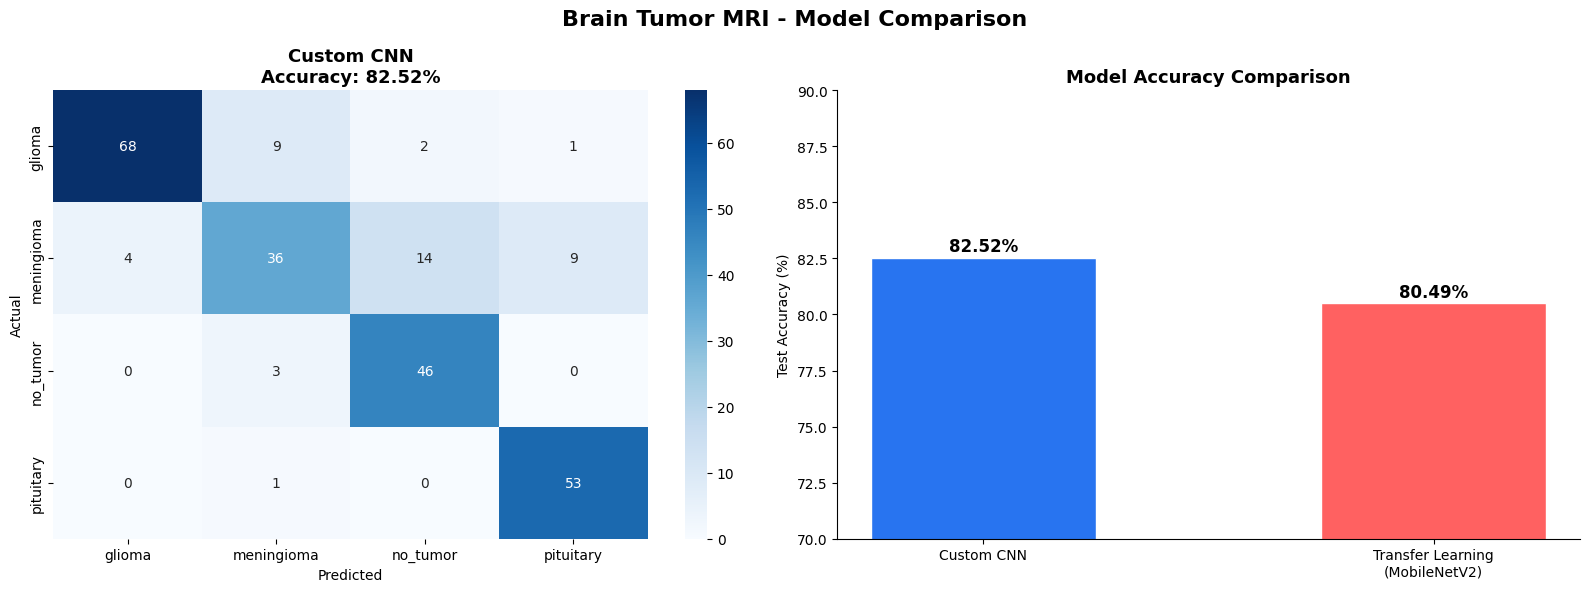


📊 Custom CNN Classification Report:
              precision    recall  f1-score   support

      glioma       0.94      0.85      0.89        80
  meningioma       0.73      0.57      0.64        63
    no_tumor       0.74      0.94      0.83        49
   pituitary       0.84      0.98      0.91        54

    accuracy                           0.83       246
   macro avg       0.82      0.84      0.82       246
weighted avg       0.83      0.83      0.82       246



In [25]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

class_labels = list(test_generator.class_indices.keys())

# Custom CNN predictions
test_generator.reset()
cnn_preds = custom_cnn.predict(test_generator, verbose=1)
cnn_pred_classes = np.argmax(cnn_preds, axis=1)
true_classes = test_generator.classes

# Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Brain Tumor MRI - Model Comparison', fontsize=16, fontweight='bold')

# Custom CNN
cm_cnn = confusion_matrix(true_classes, cnn_pred_classes)
sns.heatmap(cm_cnn, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=class_labels, yticklabels=class_labels)
axes[0].set_title(f'Custom CNN\nAccuracy: 82.52%', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Actual')
axes[0].set_xlabel('Predicted')

# Comparison bar chart
models = ['Custom CNN', 'Transfer Learning\n(MobileNetV2)']
accuracies = [82.52, 80.49]
colors = ['#2874F0', '#FF6161']
bars = axes[1].bar(models, accuracies, color=colors, edgecolor='white', width=0.5)
axes[1].set_title('Model Accuracy Comparison', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Test Accuracy (%)')
axes[1].set_ylim(70, 90)
for bar, acc in zip(bars, accuracies):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                f'{acc}%', ha='center', fontsize=12, fontweight='bold')
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

# Classification Report
print("\n📊 Custom CNN Classification Report:")
print(classification_report(true_classes, cnn_pred_classes, target_names=class_labels))

In [26]:
# Save model to Drive
custom_cnn.save('/content/drive/MyDrive/Brain Tumor MRI/brain_tumor_cnn.h5')
print("✅ Model saved to Drive!")

✅ Model saved to Drive!
